# Traveler Trip Data Analysis
Exploratory analysis and cleaning of the Kaggle *Traveler Trip Dataset* (CC BY 4.0): 139 raw trip records → 137 clean trips. The cleaned output, `data/trips_clean.csv`, is the knowledge base for the TravelJoy AI RAG pipeline.

In [1]:
import pandas as pd  
import numpy as np    

# The notebook runs from notebooks/, so data paths are relative to the project root.
df = pd.read_csv("../data/trips.csv")

df.head()  

,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type,Accommodation cost,Transportation type,Transportation cost
0,1,"London, UK",5/1/2023,5/8/2023,7.0,John Smith,35.0,Male,American,Hotel,1200,Flight,600
1,2,"Phuket, Thailand",6/15/2023,6/20/2023,5.0,Jane Doe,28.0,Female,Canadian,Resort,800,Flight,500
2,3,"Bali, Indonesia",7/1/2023,7/8/2023,7.0,David Lee,45.0,Male,Korean,Villa,1000,Flight,700
3,4,"New York, USA",8/15/2023,8/29/2023,14.0,Sarah Johnson,29.0,Female,British,Hotel,2000,Flight,1000
4,5,"Tokyo, Japan",9/10/2023,9/17/2023,7.0,Kim Nguyen,26.0,Female,Vietnamese,Airbnb,700,Train,200


In [2]:
print(df.shape)   
df.info()       


(139, 13)
<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Trip ID               139 non-null    int64  
 1   Destination           137 non-null    str    
 2   Start date            137 non-null    str    
 3   End date              137 non-null    str    
 4   Duration (days)       137 non-null    float64
 5   Traveler name         137 non-null    str    
 6   Traveler age          137 non-null    float64
 7   Traveler gender       137 non-null    str    
 8   Traveler nationality  137 non-null    str    
 9   Accommodation type    137 non-null    str    
 10  Accommodation cost    137 non-null    str    
 11  Transportation type   136 non-null    str    
 12  Transportation cost   136 non-null    str    
dtypes: float64(2), int64(1), str(10)
memory usage: 14.2 KB


In [3]:
df[df.isna().any(axis=1)]

,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type,Accommodation cost,Transportation type,Transportation cost
71,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82,83,"Rome, Italy",4/15/2025,4/22/2025,7.0,James Kim,41.0,Male,American,Hotel,100,NaN,NaN
127,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df["Accommodation cost"].unique())
print(df["Transportation cost"].unique())

<StringArray>
[    '1200',      '800',     '1000',     '2000',      '700',     '1500',
      '500',      '900',     '2500',     '3000',     '1400',      '600',
    '$900 ',  '$1,500 ',  '$1,200 ',    '$600 ',  '$1,000 ',    '$700 ',
    '$400 ',  '$1,400 ',  '$2,000 ',  '$1,100 ',    '$800 ',    '$200 ',
    '$150 ',    '$500 ',    '$180 ',    '$350 ',     '2200',      '400',
     '1100',      '300',     '1300',     '1800',        nan,  '500 USD',
 '1000 USD',  '800 USD', '1200 USD',  '400 USD',  '600 USD',  '900 USD',
 '1500 USD',  '700 USD',      '100',  '300 USD',  '200 USD',    '$300 ',
      '200',     '5000',     '7000',     '6000',     '4000',     '8000']
Length: 54, dtype: str
<StringArray>
[     '600',      '500',      '700',     '1000',      '200',      '800',
     '1200',      '100',      '400',      '150',    '$400 ',    '$700 ',
    '$150 ',    '$800 ',    '$100 ',    '$600 ',     '$80 ',    '$500 ',
    '$300 ',     '$50 ',    '$120 ',     '$75 ',      '900',       '50',


In [5]:
# Rows without a destination are fully empty. The Rome trip has a destination
# and only lacks transport details, so it is kept.
df = df.dropna(subset=["Destination"]).reset_index(drop=True)


def clean_cost(column):
    """Convert cost strings such as '$1,500 ' or '1000 USD' to numbers."""
    cleaned = (
        column.str.replace("$", "", regex=False)
              .str.replace(",", "", regex=False)
              .str.replace("USD", "", regex=False)
              .str.strip()
    )
    return pd.to_numeric(cleaned)


df["Accommodation cost"] = clean_cost(df["Accommodation cost"])
df["Transportation cost"] = clean_cost(df["Transportation cost"])

print(df.shape)
print(df[["Accommodation cost", "Transportation cost"]].dtypes)
df[["Accommodation cost", "Transportation cost"]].describe()

(137, 13)
Accommodation cost       int64
Transportation cost    float64
dtype: object


,Accommodation cost,Transportation cost
count,137.000000,136.000000
mean,1245.109489,645.183824
std,1337.349836,584.476153
min,100.000000,20.000000
25%,600.000000,200.000000
50%,900.000000,550.000000
75%,1200.000000,800.000000
max,8000.000000,3000.000000


In [6]:
df["Start date"] = pd.to_datetime(df["Start date"], format="%m/%d/%Y")
df["End date"]   = pd.to_datetime(df["End date"],   format="%m/%d/%Y")

# Integer casting is only safe after the empty rows are dropped.
df["Duration (days)"] = df["Duration (days)"].astype(int)
df["Traveler age"]    = df["Traveler age"].astype(int)

calculated = (df["End date"] - df["Start date"]).dt.days
mismatch = df[calculated != df["Duration (days)"]]
print("Rows where Duration doesn't match the dates:", len(mismatch))

df.dtypes

Rows where Duration doesn't match the dates: 10


Trip ID                          int64
Destination                        str
Start date              datetime64[us]
End date                datetime64[us]
Duration (days)                  int64
Traveler name                      str
Traveler age                     int64
Traveler gender                    str
Traveler nationality               str
Accommodation type                 str
Accommodation cost               int64
Transportation type                str
Transportation cost            float64
dtype: object

In [7]:
check = mismatch[["Trip ID", "Destination", "Start date", "End date", "Duration (days)"]].copy()
check["Calculated days"] = calculated[mismatch.index]
check["Difference"] = check["Duration (days)"] - check["Calculated days"]
check

,Trip ID,Destination,Start date,End date,Duration (days),Calculated days,Difference
82,84,Paris,2021-06-15,2021-06-20,6,5,1
83,85,Tokyo,2021-07-01,2021-07-10,10,9,1
84,86,Bali,2021-08-10,2021-08-20,11,10,1
86,88,New York,2021-10-15,2021-10-20,6,5,1
87,89,London,2021-11-20,2021-11-30,11,10,1
88,90,Dubai,2022-01-01,2022-01-08,8,7,1
89,91,Bangkok,2022-02-14,2022-02-20,7,6,1
90,92,Rome,2022-03-10,2022-03-20,11,10,1
91,93,Bali,2022-04-15,2022-04-25,11,10,1
92,94,Seoul,2022-05-01,2022-05-10,10,9,1


In [8]:
# The source mixes inclusive and exclusive day counts, so one rule
# (End date − Start date) is applied to every trip.
df["Duration (days)"] = (df["End date"] - df["Start date"]).dt.days

recheck = (df["End date"] - df["Start date"]).dt.days != df["Duration (days)"]
print("Mismatches after fix:", recheck.sum())

print(df["Destination"].unique())

Mismatches after fix: 0
<StringArray>
[                 'London, UK',            'Phuket, Thailand',
             'Bali, Indonesia',               'New York, USA',
                'Tokyo, Japan',               'Paris, France',
           'Sydney, Australia',      'Rio de Janeiro, Brazil',
      'Amsterdam, Netherlands', 'Dubai, United Arab Emirates',
              'Cancun, Mexico',            'Barcelona, Spain',
            'Honolulu, Hawaii',             'Berlin, Germany',
          'Marrakech, Morocco',         'Edinburgh, Scotland',
                       'Paris',                        'Bali',
                      'London',                       'Tokyo',
                    'New York',                      'Sydney',
                        'Rome',                     'Bangkok',
                      'Hawaii',                   'Barcelona',
                       'Japan',                    'Thailand',
                      'France',                   'Australia',
                 

In [9]:
# Destinations come in three formats: "City, Country", city only, and country only.
# Each is normalized into separate City and Country columns.
countries_only = {"Japan", "France", "Brazil", "Egypt", "Italy", "Canada",
                  "Thailand", "Australia", "Greece", "Mexico", "Spain"}

# Abbreviations and regions are mapped to the country they belong to.
country_fix = {"AUS": "Australia", "Aus": "Australia", "Thai": "Thailand",
               "SA": "South Africa", "Hawaii": "USA", "Scotland": "UK"}

city_fix = {"New York City": "New York"}

city_to_country = {"Paris": "France", "London": "UK", "Bali": "Indonesia",
                   "Tokyo": "Japan", "New York": "USA", "Sydney": "Australia",
                   "Rome": "Italy", "Bangkok": "Thailand", "Barcelona": "Spain",
                   "Cape Town": "South Africa", "Seoul": "South Korea",
                   "Dubai": "United Arab Emirates", "Rio de Janeiro": "Brazil",
                   "Amsterdam": "Netherlands", "Phuket": "Thailand",
                   "Santorini": "Greece", "Phnom Penh": "Cambodia", "Hawaii": "USA"}

def split_destination(dest):
    """Split a raw destination into City and Country, inferring the country from the city when absent."""

    if ", " in dest:                  
        city, country = dest.split(", ", 1)
    elif dest in countries_only:         
        city, country = None, dest
    else:                              
        city, country = dest, None
    city = city_fix.get(city, city)                
    country = country_fix.get(country, country)       
    if country is None:
        country = city_to_country.get(city)          
    return pd.Series([city, country])

df[["City", "Country"]] = df["Destination"].apply(split_destination)

df["Country"].value_counts(dropna=False)

Country
France                  15
USA                     13
Japan                   13
Australia               13
Thailand                12
Indonesia               12
Italy                   10
UK                       8
Spain                    7
Brazil                   6
Mexico                   5
South Africa             4
Netherlands              3
United Arab Emirates     3
Greece                   3
Canada                   3
South Korea              2
Germany                  1
Morocco                  1
Egypt                    1
Cambodia                 1
New Zealand              1
Name: count, dtype: int64

In [10]:
for col in ["Accommodation type", "Transportation type", "Traveler gender", "Traveler nationality"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Accommodation type ---
Accommodation type
Hotel              60
Airbnb             30
Hostel             24
Resort             14
Villa               4
Vacation rental     3
Riad                1
Guesthouse          1
Name: count, dtype: int64

--- Transportation type ---
Transportation type
Plane         57
Train         37
Flight        13
Car rental    13
Bus            6
Airplane       5
Car            3
Subway         1
NaN            1
Ferry          1
Name: count, dtype: int64

--- Traveler gender ---
Traveler gender
Female    70
Male      67
Name: count, dtype: int64

--- Traveler nationality ---
Traveler nationality
American                24
Korean                  13
British                 12
Canadian                 9
Australian               8
Spanish                  7
Chinese                  7
Brazilian                4
Italian                  4
Indian                   4
Vietnamese               3
South Korean             3
South Korea              3
Dutch       

In [11]:
transport_fix = {"Plane": "Flight", "Airplane": "Flight", "Car rental": "Car"}
df["Transportation type"] = df["Transportation type"].replace(transport_fix)

nationality_fix = {
    "USA": "American", "Canada": "Canadian", "UK": "British",
    "United Kingdom": "British", "Scottish": "British",
    "Korean": "South Korean", "South Korea": "South Korean",
    "Taiwan": "Taiwanese", "China": "Chinese", "Japan": "Japanese",
    "Spain": "Spanish", "Brazil": "Brazilian", "Germany": "German",
    "Italy": "Italian", "Greece": "Greek", "United Arab Emirates": "Emirati",
    "Cambodia": "Cambodian", "Singapore": "Singaporean",
    "Hong Kong": "Hongkonger",
}
df["Traveler nationality"] = df["Traveler nationality"].replace(nationality_fix)

print(df["Transportation type"].value_counts(dropna=False))
print()
print("Nationalities before: 41 → after:", df["Traveler nationality"].nunique())
df["Traveler nationality"].value_counts().head(10)

Transportation type
Flight    75
Train     37
Car       16
Bus        6
Subway     1
NaN        1
Ferry      1
Name: count, dtype: int64

Nationalities before: 41 → after: 26


Traveler nationality
American        26
South Korean    19
British         15
Canadian        11
Australian       8
Spanish          8
Chinese          8
Brazilian        5
Italian          5
Indian           4
Name: count, dtype: int64

In [12]:
# A missing transport cost leaves the total empty rather than understating it.
df["Total cost"] = df["Accommodation cost"] + df["Transportation cost"]

df.to_csv("../data/trips_clean.csv", index=False)

print("Saved:", df.shape)
df[["City", "Country", "Duration (days)", "Accommodation cost", "Transportation cost", "Total cost"]].head()

Saved: (137, 16)


,City,Country,Duration (days),Accommodation cost,Transportation cost,Total cost
0,London,UK,7,1200,600.0,1800.0
1,Phuket,Thailand,5,800,500.0,1300.0
2,Bali,Indonesia,7,1000,700.0,1700.0
3,New York,USA,14,2000,1000.0,3000.0
4,Tokyo,Japan,7,700,200.0,900.0


In [13]:
# Cost per day normalizes for trip length, since longer trips naturally cost more.
df["Cost per day"] = df["Total cost"] / df["Duration (days)"]

# Medians resist outliers; countries with fewer than 3 trips are excluded as unreliable.
by_country = (df.groupby("Country")["Total cost"]
                .agg(trips="count", median_cost="median")
                .query("trips >= 3")
                .sort_values("median_cost", ascending=False))
print("Q1: Most expensive countries")
display(by_country)

by_stay = (df.groupby("Accommodation type")["Accommodation cost"]
             .agg(trips="count", median_cost="median")
             .sort_values("median_cost", ascending=False))
print("Q2: Accommodation types")
display(by_stay)

by_transport = (df.groupby("Transportation type")["Transportation cost"]
                  .agg(trips="count", median_cost="median")
                  .sort_values("median_cost"))
print("Q3: Transport types")
display(by_transport)

print("Q4: Typical cost per day:", round(df["Cost per day"].median()), "USD")

Q1: Most expensive countries


,trips,median_cost
Country,,
USA,13,2000.0
Indonesia,12,1850.0
United Arab Emirates,3,1800.0
Australia,13,1500.0
South Africa,4,1500.0
Mexico,5,1500.0
France,15,1500.0
Brazil,6,1400.0
Netherlands,3,1400.0


Q2: Accommodation types


,trips,median_cost
Accommodation type,,
Resort,14,1500.0
Villa,4,1350.0
Hotel,60,1100.0
Vacation rental,3,900.0
Airbnb,30,750.0
Riad,1,600.0
Hostel,24,400.0
Guesthouse,1,400.0


Q3: Transport types


,trips,median_cost
Transportation type,,
Subway,1,20.0
Bus,6,62.5
Train,37,150.0
Ferry,1,150.0
Car,16,300.0
Flight,75,800.0


Q4: Typical cost per day: 189 USD


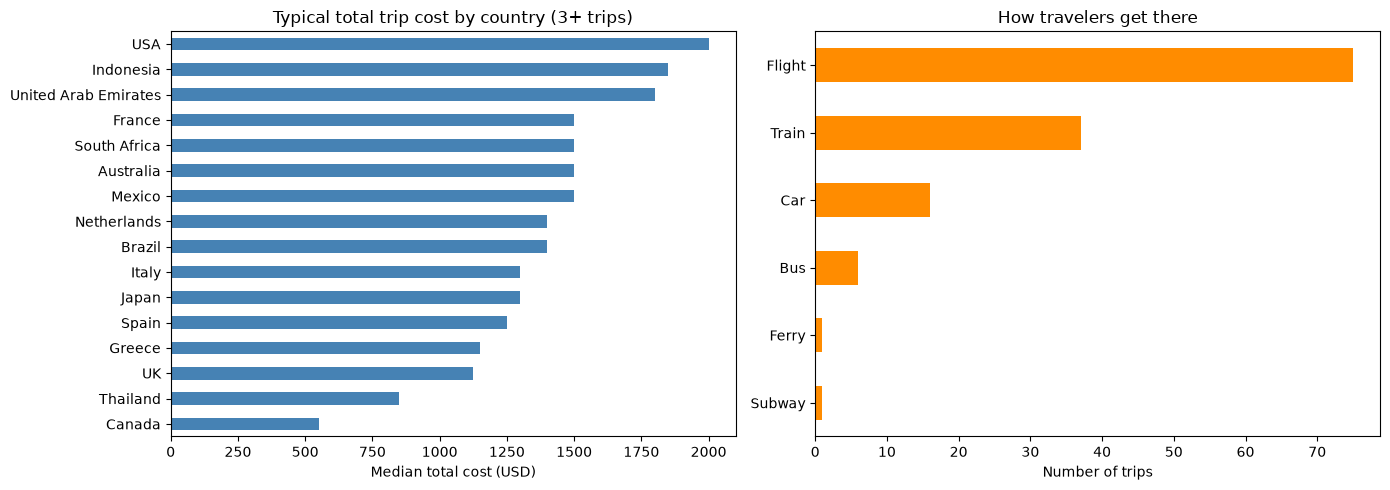

In [14]:
import matplotlib.pyplot as plt 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

by_country["median_cost"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Typical total trip cost by country (3+ trips)")
axes[0].set_xlabel("Median total cost (USD)")
axes[0].set_ylabel("")

by_transport["trips"].sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("How travelers get there")
axes[1].set_xlabel("Number of trips")
axes[1].set_ylabel("")

plt.tight_layout()  
plt.show()

## Data cleaning summary
- Dropped 2 fully empty rows (139 → 137 trips)
- Converted costs from 3 text formats (`1200`, `$1,200 `, `1200 USD`) to numbers
- Converted dates from text to real dates
- Recalculated 10 durations that used inclusive day counting (off by 1)
- Split messy destinations (59 spellings) into clean `City` + `Country` (24 countries)
- Standardized transport (`Plane`/`Airplane` → `Flight`) and nationality names (41 → 26)

## Key findings
- **USA** has the highest typical trip cost (~$2,000); **Thailand** (~$850) and **Canada** (~$550) the lowest
- **Resorts** cost ~4× more than **hostels** ($1,500 vs $400 median)
- **Flights** are the most common transport (75 trips); **trains** are ~5× cheaper ($150 vs $800)
- A typical trip day costs about **$189**

## Limitations
- Small sample (137 trips); some groups have only 1–3 trips, so treat them as hints
- Prices are from 2021–2025 and not verified